In [1]:
import qlib
from qlib.config import REG_US # [REG_CN, REG_US]

from qlib.data.dataset.loader import QlibDataLoader
from qlib.data.dataset.handler import DataHandler, DataHandlerLP

from qlib.contrib.strategy.strategy import BaseStrategy, ListAdjustTimer

from qlib.utils import init_instance_by_config
from qlib.workflow import R
from qlib.workflow.record_temp import SignalRecord, PortAnaRecord
from qlib.utils import flatten_dict

import optuna

import pandas as pd
import numpy as np

import math

import sys


# Define directory depth
directory_depth = "../../../"


# Add custom library to path
sys.path.append(directory_depth + "Custom_Library")
print("Path added successfully: " + directory_depth + "Custom_Library")

# Init Qlib
provider_uri = directory_depth + "Database\Qdata\SPAIN"  # target_dir
qlib.init(provider_uri=provider_uri, region=REG_US)
print("Qlib version: " + str(qlib.__version__))

Path added successfully: ../../../../Custom_Library
[1580:MainThread](2022-01-04 19:18:40,832) INFO - qlib.Initialization - [config.py:287] - default_conf: client.
[1580:MainThread](2022-01-04 19:18:42,840) WARNING - qlib.Initialization - [config.py:303] - redis connection failed(host=127.0.0.1 port=6379), cache will not be used!
[1580:MainThread](2022-01-04 19:18:42,848) INFO - qlib.Initialization - [__init__.py:54] - qlib successfully initialized based on client settings.
[1580:MainThread](2022-01-04 19:18:42,850) INFO - qlib.Initialization - [__init__.py:55] - data_path=D:\Proyects\Investing\Quantitative\Database\Qdata\BME
Qlib version: 0.7.0


In [2]:
instruments = 'all'
benchmark = '^ibex'

In [3]:
###################################
# Define DataLoader
###################################
from qlib_expansion import qdatasets, qfilters

##################################################################################################################
# --------------
# Features
# --------------

fields, names = qdatasets.dataset_features_ts()

##################################################################################################################
# --------------
# Labels
# --------------

# labels = ['''((Ref($open, -2) / Ref($open, -1)) - 1)''']
labels = ['''((EMA(Ref($open, -5), 5) / Ref($open, -1)) - 1)''']
# labels = ['''((EMA(Ref($open, -5), 5) / EMA($open, 5)) - 1)''']

label_names = ['label']

##################################################################################################################
# --------------
# Filters
# --------------

filters = qfilters.Filters()

# Label filter
label_filters = filters.generate_label_filters(expression=labels[0], threshold=0.8)

# Filter pipe
filter_pipe = label_filters + filters.basic + filters.spain


##################################################################################################################
##################################################################################################################
# ----------------------------
# Initialize data loader
# ----------------------------

data_loader = QlibDataLoader(config={"feature": (fields, names), "label": (labels, label_names)},
                             filter_pipe=filter_pipe, freq="day")

print(data_loader)
print("Number of features == " + str(len(fields)))

Number of features == 185


In [4]:
###################################
# Define DataHandler
###################################

defined_DataHandler = DataHandlerLP(instruments=instruments,
                                    # start_time='2000-01-01',
                                    # end_time='2022-01-01',
                                    data_loader=data_loader,
                                    infer_processors=[
                                           # {"class": "ProcessInf", "kwargs": {}},
                                           # {"class": "ZScoreNorm", "kwargs": {"fit_start_time": '2000-01-01', "fit_end_time": '2016-12-31'}},
                                           # {"class": "Fillna", "kwargs": {"fields_group": "feature", "fill_value": 0}},
                                           # {"class": "DropnaProcessor", "kwargs": {'fields_group': 'feature'}},
                                       ],
                                    learn_processors=[
                                           {"class": "DropnaLabel"},
                                           # {"class": "CSZScoreNorm", "kwargs": {"fields_group": "label"}},
                                       ]
                                    )


[1580:MainThread](2022-01-04 19:20:21,182) INFO - qlib.timer - [log.py:113] - Time cost: 98.200s | Loading data Done
[1580:MainThread](2022-01-04 19:20:21,709) INFO - qlib.timer - [log.py:113] - Time cost: 0.437s | DropnaLabel Done
[1580:MainThread](2022-01-04 19:20:21,712) INFO - qlib.timer - [log.py:113] - Time cost: 0.528s | fit & process data Done
[1580:MainThread](2022-01-04 19:20:21,718) INFO - qlib.timer - [log.py:113] - Time cost: 98.735s | Init data Done


In [5]:
###################################
# Define task
###################################

task = {
    "model": {
            "class": "LGBModel",
            "module_path": "qlib.contrib.model.gbdt",
            "kwargs": {
                'loss': 'mse',
                'learning_rate': 0.01,
                'max_depth': -1,
                'lambda_l1': 0,
                'lambda_l2': 0,
                'num_leaves': 31,
                'min_data_in_leaf': 20,
                'feature_fraction': 1,
                'bagging_fraction': 1,
                'bagging_freq': 0
            },
    },
    "dataset": {
        "class": "DatasetH",
        "module_path": "qlib.data.dataset",
        "kwargs": {
            "handler": defined_DataHandler,
            "segments": {
                "train": ("2000-01-01", "2016-12-31"),
                "valid": ("2017-01-01", "2018-12-31"),
                "test": ("2019-01-01", "2021-12-31"),
            },
        },
    },
}


###################################
# Initialize dataset
###################################

dataset = init_instance_by_config(task["dataset"])

print(dataset)

DatasetH(handler=<qlib.data.dataset.handler.DataHandlerLP object at 0x00000210685D0940>, segments={'train': ('2000-01-01', '2016-12-31'), 'valid': ('2017-01-01', '2018-12-31'), 'test': ('2019-01-01', '2021-12-31')})


In [6]:
###################################
# Hyperparameter tuning
###################################

tune = False


if tune:
    print("Using Optuna to find best parameters...")

    def objective(trial):
        tuning_task = {
            "model": {
                "class": "LGBModel",
                "module_path": "qlib.contrib.model.gbdt",
                "kwargs": {
                    "loss": "mse",
                    
                    "learning_rate": trial.suggest_uniform("learning_rate", 0.001, 0.1),
                    "max_depth": trial.suggest_int("max_depth", 5, 30),

                    "lambda_l1": trial.suggest_loguniform("lambda_l1", 1e-8, 1e4),
                    "lambda_l2": trial.suggest_loguniform("lambda_l2", 1e-8, 1e4),
                    
                    "num_leaves": trial.suggest_int("num_leaves", 2, 1024),
                    "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 250),

                    "feature_fraction": trial.suggest_uniform("feature_fraction", 0.4, 1.0),
                    "bagging_fraction": trial.suggest_uniform("bagging_fraction", 0.4, 1.0),
                    "bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
                },
            },
        }
        print("Trial params: " + str(tuning_task["model"]["kwargs"]))

        evals_result = dict()
        model = init_instance_by_config(tuning_task["model"])
        model.fit(dataset, evals_result=evals_result, num_boost_round=100000, verbose_eval=100000, early_stopping_rounds=50)

        print("==============================================================================================================================")
        return min(evals_result["valid"])


    study = optuna.create_study(direction='minimize', pruner=optuna.pruners.SuccessiveHalvingPruner())
    '''
    study = optuna.create_study(
        direction='minimize',
        pruner=optuna.pruners.HyperbandPruner(min_resource=1, max_resource=100000, reduction_factor=3)
    )
    '''

    study.optimize(objective, n_jobs=1, n_trials=50, gc_after_trial=True)

    print("Best parameters found:")
    print(study.best_params)

    task["model"]["kwargs"] = study.best_params


In [7]:
###################################
# Train model
###################################


# Model Initialization
model = init_instance_by_config(task["model"])


# start exp to train model
with R.start():
    R.log_params(**flatten_dict(task))
    model.fit(dataset, num_boost_round=1000, verbose_eval=20, early_stopping_rounds=0)
    
    R.save_objects(trained_model=model)

    rid = R.get_recorder().id


[1580:MainThread](2022-01-04 19:20:25,147) INFO - qlib.workflow - [expm.py:261] - No tracking URI is provided. Use the default tracking URI.
[1580:MainThread](2022-01-04 19:20:25,150) INFO - qlib.workflow - [expm.py:297] - <mlflow.tracking.client.MlflowClient object at 0x000002107C4F7400>
[1580:MainThread](2022-01-04 19:20:25,189) INFO - qlib.workflow - [exp.py:249] - Experiment 1 starts running ...
[1580:MainThread](2022-01-04 19:20:25,550) INFO - qlib.workflow - [recorder.py:283] - Recorder c2a8dd21676e4b59bfa8411eadbd460e starts running under Experiment 1 ...
[20]	train's l2: 0.000825948	valid's l2: 0.000479665
[40]	train's l2: 0.0008153	valid's l2: 0.0004774
[60]	train's l2: 0.000806586	valid's l2: 0.000475996
[80]	train's l2: 0.000799075	valid's l2: 0.000474987
[100]	train's l2: 0.000792486	valid's l2: 0.000474404
[120]	train's l2: 0.000786518	valid's l2: 0.000473943
[140]	train's l2: 0.000780792	valid's l2: 0.000473727
[160]	train's l2: 0.000775214	valid's l2: 0.000473834
[180]	t

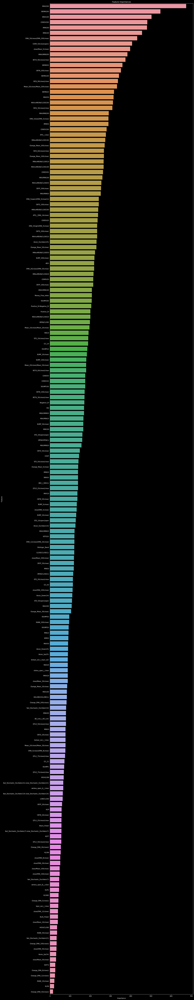

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


# Get feature importances
feature_importances = model.get_feature_importance()

if len(feature_importances):
    feature_importances = pd.DataFrame({'Feature': feature_importances.index, 'Importance': feature_importances})

    # Display as barplot
    plt.figure(figsize=(18, len(feature_importances) // 2))
    sns.barplot(x="Importance", y="Feature",
                data=feature_importances.sort_values(by="Importance", ascending=False))
    plt.title('Feature Importances')
    plt.tight_layout()
    plt.show()
else:
    print("No feature importances? Something must be wrong...")

In [9]:
###################################
# prediction, backtest & analysis
###################################
from qlib_expansion import strategies



stop_loss_logics_sample = [
    """
        $close - 1.5 * Mean(
            Greater(
                $high-$low,
                Greater(
                    Abs($high-Ref($close, 1)),
                    Abs($low-Ref($close, 1))
                )
            ),
            20
        )
    """,
    """
        $low - 1.5 * Mean(
            Greater(
                $high-$low,
                Greater(
                    Abs($high-Ref($close, 1)),
                    Abs($low-Ref($close, 1))
                )
            ),
            14
        )
    """,
    """((Mean($close, 20) - 2 * Std($close, 20)))"""
]
stop_loss_logics = [stop_loss_logics_sample[0]]



port_analysis_config = {
    # "strategy": strategies.BasicStrategy(investment_percentage=0.01),
    "strategy": strategies.KellyCriterionStrategy(max_invest=0.25, stop_loss_logics=stop_loss_logics, soft_stop_loss=True),

    "backtest": {
        "verbose": False,
        "account": 10000,
        "benchmark": benchmark,
        "deal_price": "open",

        # "open_cost": 0,
        # "close_cost": 0,
        # "min_cost": 0,
        "open_cost": 0.0005,
        "close_cost": 0.0005,
        "min_cost": 2,
    },
}


# backtest and analysis
with R.start(experiment_name='test', recorder_name='test_recorder'):
    # recorder = R.get_recorder(recorder_id=rid, experiment_name="train")
    # model = recorder.load_object("trained_model")

    # prediction
    recorder = R.get_recorder()
    ba_rid = recorder.id
    sr = SignalRecord(model, dataset, recorder)
    sr.generate()

    # backtest & analysis
    par = PortAnaRecord(recorder, port_analysis_config)
    par.generate()


Stop_Loss basic market DataHandler initializing...
[1580:MainThread](2022-01-04 19:21:37,224) INFO - qlib.timer - [log.py:113] - Time cost: 3.727s | Loading data Done
[1580:MainThread](2022-01-04 19:21:37,229) INFO - qlib.timer - [log.py:113] - Time cost: 3.733s | Init data Done
Stop_Loss thresholds DataHandler initializing...
[1580:MainThread](2022-01-04 19:21:42,072) INFO - qlib.timer - [log.py:113] - Time cost: 4.806s | Loading data Done
[1580:MainThread](2022-01-04 19:21:42,074) INFO - qlib.timer - [log.py:113] - Time cost: 4.807s | Init data Done
[1580:MainThread](2022-01-04 19:21:42,077) INFO - qlib.workflow - [expm.py:261] - No tracking URI is provided. Use the default tracking URI.
[1580:MainThread](2022-01-04 19:21:42,083) INFO - qlib.workflow - [expm.py:297] - <mlflow.tracking.client.MlflowClient object at 0x00000210181F7F98>
[1580:MainThread](2022-01-04 19:21:42,092) INFO - qlib.workflow - [exp.py:249] - Experiment 2 starts running ...
[1580:MainThread](2022-01-04 19:21:42,1

# Analyze Graphs

In [10]:
from qlib.contrib.report import analysis_model, analysis_position
from qlib.data import D

recorder = R.get_recorder(recorder_id=ba_rid)

pred_df = recorder.load_object("pred.pkl")
pred_df_dates = pred_df.index.get_level_values(level='datetime')
report_normal_df = recorder.load_object("portfolio_analysis/report_normal.pkl")
positions = recorder.load_object("portfolio_analysis/positions_normal.pkl")
analysis_df = recorder.load_object("portfolio_analysis/port_analysis.pkl")

## Analysis Position
### Report

In [11]:
analysis_position.report_graph(report_normal_df)

### Risk Analysis

In [12]:
analysis_position.risk_analysis_graph(analysis_df, report_normal_df)

## Analysis Model

In [13]:
label_df = dataset.prepare("test", col_set="label")
label_df.columns = ['label']

pred_label = pd.concat([label_df, pred_df], axis=1, sort=True).reindex(label_df.index)

pred_label

label     score
datetime   instrument                    
2019-01-02 ACX.MC      0.052659  0.001050
           AENA.MC     0.021412  0.000642
           ALM.MC      0.043462  0.000569
           AMS.MC      0.007030  0.001382
           ANA.MC      0.032454  0.000093
...                         ...       ...
2021-12-30 SLR.MC     -0.013797  0.001471
           TEF.MC      0.028718  0.002193
           TL5.MC     -0.016053 -0.003348
           UNI.MC      0.007177  0.002126
           VIS.MC     -0.001179  0.000815

[32383 rows x 2 columns]

### Score IC

In [14]:
analysis_position.score_ic_graph(pred_label)

### Model Performance

In [15]:
analysis_model.model_performance_graph(pred_label)

In [16]:
# Save positions
positions_df = pd.DataFrame.from_dict(positions, orient='index')

positions_df.to_csv("Analysis/Positions.csv")